In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path
# make `evqaoa` and `experiments` importable whether the notebook runs from notebooks/ or the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'evqaoa').is_dir())
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'results' / '04_optimizers'
OUT.mkdir(parents=True, exist_ok=True)

# 04 - Which optimizer? And does CVaR help?

## Motivation
QAOA is a *hybrid* algorithm: a quantum circuit with angles `(betas, gammas)` produces a bitstring distribution, and a **classical optimizer** tunes the angles to lower the expected energy of the EV-charging cost function. The upstream prototype used **COBYLA capped at 30 evaluations** with **p = 1** on hardware. The hackathon organisers suggest "check effects of optimizers", so here we ask:

1. **Which optimizer** reaches a good schedule with the fewest circuit evaluations (every evaluation costs real hardware time)?
2. **Which survive shot noise?** On hardware you never see the exact energy, only an average over a finite number of shots.
3. **Does CVaR help?** Instead of the average of all sampled energies, CVaR-alpha (Barkoutsas et al. 2020) averages only the best `alpha` fraction of shots. We care about finding the *best schedule*, not a good average, so this may be a better target.

## Workflow
Instance: `EXAMPLE_3x4` (3 vehicles x 4 slots = 12 qubits, 216 valid schedules), XY mixer + Dicke start (always valid schedules), weights `lam=(0.5, 0.3, 0.2)`.
1. Build the circuit and precompute the QUBO energy of every bitstring so any angle setting is evaluated fast from statevector probabilities.
2. **Exp 1** - five optimizers, exact energy, same random starts, count evaluations.
3. **Exp 2** - same optimizers with sampled (256 / 1024-shot) energies.
4. **Exp 3** - CVaR alpha in {0.1, 0.25, 0.5, 1.0} under shots.

All final angles are judged with the **exact** statevector, so noise only affects the optimisation, not the scoring.

Metrics: *approximation ratio* = (E_worst - E) / (E_worst - E_best) over valid schedules (1 = always optimal); *P(optimal)* = probability of the best schedule; *P(within 1%)* = probability of any schedule with energy <= 1.01 x E_best.

In [3]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector
from evqaoa import (EXAMPLE_3x4, build_qubo, qubo_to_hamiltonian, build_qaoa,
                    brute_force_baselines, objective_scales, expectation_energy)
from experiments.optimizers import run_optimizer, sample_energies, cvar

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
T0 = time.time()
inst = EXAMPLE_3x4
Q, const = build_qubo(inst, lam=(0.5, 0.3, 0.2), scale=objective_scales(inst), penalty=0.0)
H = qubo_to_hamiltonian(Q, const)
E_mean, E_best, E_worst = brute_force_baselines(inst, Q, const)

# QUBO energy of every 12-bit string (bit i of the index = qubit i, little-endian like Qiskit)
idx = np.arange(2 ** inst.n)
bits = ((idx[:, None] >> np.arange(inst.n)) & 1).astype(float)
ENERGY = np.einsum('ij,jk,ik->i', bits, Q, bits) + const
N_GOOD = int((ENERGY <= E_best * 1.01).sum())
print(f'random-schedule mean {E_mean:.4f} | best {E_best:.4f} | worst {E_worst:.4f}')
is_valid = (bits.reshape(-1, inst.V, inst.T).sum(axis=2) == np.array(inst.need)).all(axis=1)
print(f'valid schedules tied at the best energy: {int((is_valid & (np.abs(ENERGY - E_best) < 1e-9)).sum())}; '
      f'valid schedules within 1% of it: {int((is_valid & (ENERGY <= E_best * 1.01)).sum())} (of {int(is_valid.sum())} valid)')

random-schedule mean 0.6548 | best 0.5175 | worst 0.9333
valid schedules tied at the best energy: 6; valid schedules within 1% of it: 6 (of 216 valid)


In [4]:
CIRCUITS = {p: build_qaoa(inst, H, p, mixer='xy', start='dicke') for p in (1, 2)}

def probs_of(p, theta):
    return Statevector(CIRCUITS[p].assign_parameters(theta)).probabilities()

# sanity check: our fast energy table equals the library's exact expectation value
th = np.random.default_rng(0).uniform(0, np.pi, 4)
assert abs(probs_of(2, th) @ ENERGY - expectation_energy(CIRCUITS[2], H)(th)) < 1e-9

VALID = np.isclose(ENERGY[:, None], ENERGY[None, :]).any(axis=1)  # placeholder, not used for scoring
def final_metrics(p, theta):
    """Score angles with the exact statevector (no shot noise)."""
    pr = probs_of(p, theta)
    e = float(pr @ ENERGY)
    return dict(energy=e,
                approx_ratio=(E_worst - e) / (E_worst - E_best),
                p_optimal=float(pr[np.abs(ENERGY - E_best) < 1e-9].sum()),
                p_within_1pct=float(pr[ENERGY <= E_best * 1.01].sum()))

def exact_objective(p):
    return lambda th: float(probs_of(p, th) @ ENERGY)

def shot_objective(p, shots, rng, alpha=1.0):
    """Noisy objective: CVaR-alpha of `shots` sampled energies (alpha=1 -> ordinary mean)."""
    return lambda th: cvar(sample_energies(probs_of(p, th), ENERGY, shots, rng), alpha)

def start_point(p, seed):
    return np.random.default_rng(seed).uniform(0, np.pi, 2 * p)   # [betas..., gammas...]

CHECK_STRIDE = 10
def convergence_curve(p, res, budget):
    """Exact energy of the best-so-far (by observed value) point, checked every CHECK_STRIDE evaluations."""
    vals, pts = np.array(res['values']), res['points']
    out = []
    for n in range(CHECK_STRIDE, budget + 1, CHECK_STRIDE):
        m = min(n, len(vals))
        out.append(float(probs_of(p, pts[int(np.argmin(vals[:m]))]) @ ENERGY))
    return out

def summarise(rows):
    keys = ['approx_ratio', 'p_optimal', 'p_within_1pct', 'nfev']
    s = {k: (float(np.mean([r[k] for r in rows])), float(np.std([r[k] for r in rows]))) for k in keys}
    s['success_rate'] = float(np.mean([r['approx_ratio'] >= SUCCESS_RATIO for r in rows]))
    return s

SUCCESS_RATIO = 0.80   # a run "succeeds" if its final approximation ratio is >= 0.80 (best reachable at p=1 is about 0.82)
METHODS = ['COBYLA', 'Nelder-Mead', 'Powell', 'L-BFGS-B', 'SPSA']

## Experiment 1 - optimizer comparison with the exact energy
Every optimizer gets the **same random starting angles** for each of 8 seeds and a budget of 200 circuit evaluations. `COBYLA (cap 30)` reproduces the upstream setting. SPSA is our own 25-line implementation (2 evaluations per step regardless of the number of parameters). L-BFGS-B must estimate its gradient by finite differences, so each gradient costs `2p + 1` evaluations.

In [5]:
BUDGET, SEEDS_EXACT = 200, list(range(8))
CONFIGS = [(m, BUDGET) for m in METHODS] + [('COBYLA', 30)]
def label(m, b): return 'COBYLA (cap 30)' if b == 30 else m

exp1, exp1_curves = {}, {}
for p in (1, 2):
    f = exact_objective(p)
    for m, b in CONFIGS:
        rows, curves = [], []
        for s in SEEDS_EXACT:
            res = run_optimizer(f, start_point(p, s), m, b, seed=s)
            rows.append({**final_metrics(p, res['x']), 'nfev': res['nfev']})
            curves.append(convergence_curve(p, res, BUDGET))
        exp1[(p, label(m, b))] = summarise(rows)
        exp1_curves[(p, label(m, b))] = np.array(curves)
print(f'Experiment 1 done  ({time.time() - T0:.0f}s elapsed)')
print(f"{'p':>2} {'optimizer':<16}{'approx ratio':>14}{'P(opt)':>10}{'P(<=1%)':>10}{'evals':>8}{'success':>9}")
for (p, name), s in exp1.items():
    print(f"{p:>2} {name:<16}{s['approx_ratio'][0]:>8.3f}+-{s['approx_ratio'][1]:.3f}{s['p_optimal'][0]:>10.3f}"
          f"{s['p_within_1pct'][0]:>10.3f}{s['nfev'][0]:>8.0f}{s['success_rate']:>9.0%}")

Experiment 1 done  (141s elapsed)
 p optimizer         approx ratio    P(opt)   P(<=1%)   evals  success
 1 COBYLA             0.692+-0.022     0.029     0.029     200       0%
 1 Nelder-Mead        0.822+-0.000     0.106     0.106     133     100%
 1 Powell             0.822+-0.000     0.106     0.106      85     100%
 1 L-BFGS-B           0.822+-0.000     0.106     0.106      78     100%
 1 SPSA               0.674+-0.005     0.027     0.027     199       0%
 1 COBYLA (cap 30)    0.681+-0.011     0.027     0.027      30       0%
 2 COBYLA             0.839+-0.016     0.154     0.154     200     100%
 2 Nelder-Mead        0.860+-0.009     0.129     0.129     200     100%
 2 Powell             0.868+-0.013     0.134     0.134     181     100%
 2 L-BFGS-B           0.867+-0.007     0.159     0.159     161     100%
 2 SPSA               0.751+-0.048     0.089     0.089     199      25%
 2 COBYLA (cap 30)    0.822+-0.033     0.143     0.143      30      88%


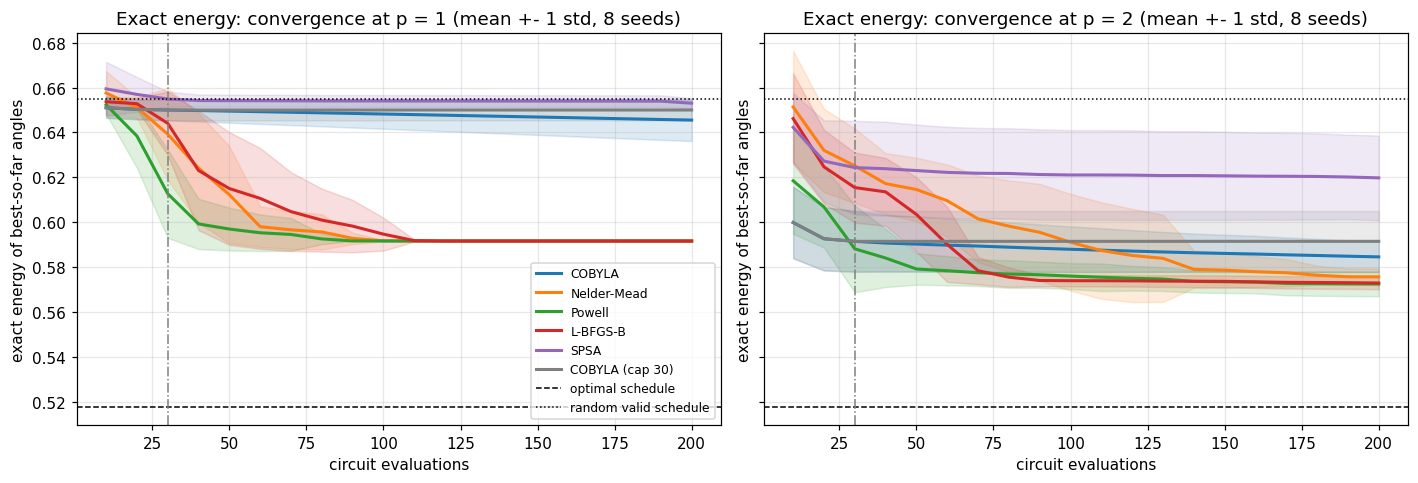

In [6]:
COLORS = {'COBYLA': '#1f77b4', 'Nelder-Mead': '#ff7f0e', 'Powell': '#2ca02c', 'L-BFGS-B': '#d62728',
          'SPSA': '#9467bd', 'COBYLA (cap 30)': '#7f7f7f'}
xs = np.arange(CHECK_STRIDE, BUDGET + 1, CHECK_STRIDE)

def plot_curves(ax, curves, p, title):
    for name, c in curves.items():
        if name[0] != p: continue
        mu, sd = c.mean(0), c.std(0)
        ax.plot(xs, mu, color=COLORS[name[1]], label=name[1], lw=2)
        ax.fill_between(xs, mu - sd, mu + sd, color=COLORS[name[1]], alpha=0.15)
    ax.axhline(E_best, color='k', ls='--', lw=1, label='optimal schedule')
    ax.axhline(E_mean, color='k', ls=':', lw=1, label='random valid schedule')
    ax.axvline(30, color='gray', ls='-.', lw=1)
    ax.set_title(title); ax.set_xlabel('circuit evaluations'); ax.set_ylabel('exact energy of best-so-far angles')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, p in zip(axes, (1, 2)):
    plot_curves(ax, exp1_curves, p, f'Exact energy: convergence at p = {p} (mean +- 1 std, 8 seeds)')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'convergence_exact.png'); plt.show()

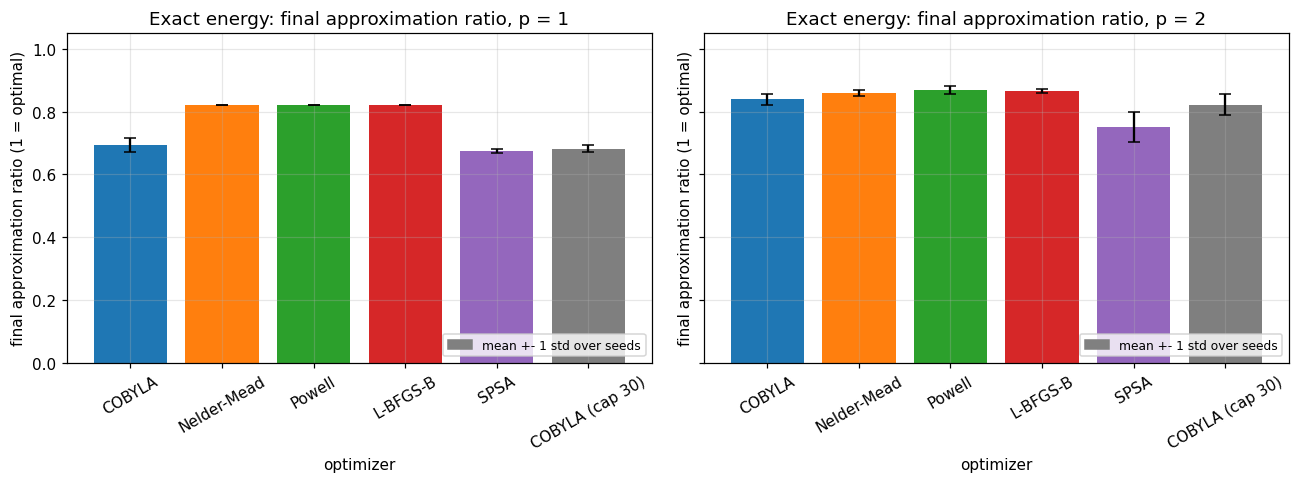

In [7]:
def bar_chart(ax, stats, p, title, metric='approx_ratio'):
    names = [k[1] for k in stats if k[0] == p]
    mu = [stats[(p, n)][metric][0] for n in names]
    sd = [stats[(p, n)][metric][1] for n in names]
    ax.bar(names, mu, yerr=sd, capsize=4, color=[COLORS[n] for n in names])
    ax.set_title(title); ax.set_ylabel('final approximation ratio (1 = optimal)'); ax.set_xlabel('optimizer')
    ax.tick_params(axis='x', rotation=30); ax.set_ylim(0, 1.05)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color='gray')], ['mean +- 1 std over seeds'], fontsize=8, loc='lower right')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, p in zip(axes, (1, 2)):
    bar_chart(ax, exp1, p, f'Exact energy: final approximation ratio, p = {p}')
plt.tight_layout(); plt.savefig(OUT / 'approx_ratio_exact.png'); plt.show()

## Experiment 2 - the same optimizers with shot noise
Now the objective is the **mean of `shots` sampled energies** (multinomial sampling of the statevector probabilities). Each run has its own fixed random stream, so results are reproducible. The final angles are still scored exactly. Budget 200 evaluations, 6 seeds, p = 1 and 2.

In [8]:
SEEDS_NOISY, BUDGET_N = list(range(6)), 200
xs_n = np.arange(CHECK_STRIDE, BUDGET_N + 1, CHECK_STRIDE)
exp2, exp2_curves = {}, {}
for shots in (256, 1024):
    for p in (1, 2):
        for m in METHODS:
            rows, curves = [], []
            for s in SEEDS_NOISY:
                f = shot_objective(p, shots, np.random.default_rng(1000 + s))
                res = run_optimizer(f, start_point(p, s), m, BUDGET_N, seed=s)
                rows.append({**final_metrics(p, res['x']), 'nfev': res['nfev']})
                curves.append(convergence_curve(p, res, BUDGET_N))
            exp2[(shots, p, m)] = summarise(rows)
            exp2_curves[(shots, p, m)] = np.array(curves)
print(f'Experiment 2 done  ({time.time() - T0:.0f}s elapsed)')
print(f"{'shots':>5} {'p':>2} {'optimizer':<13}{'approx ratio':>14}{'P(opt)':>9}{'evals':>7}{'success':>9}")
for (shots, p, m), s in exp2.items():
    print(f"{shots:>5} {p:>2} {m:<13}{s['approx_ratio'][0]:>8.3f}+-{s['approx_ratio'][1]:.3f}{s['p_optimal'][0]:>9.3f}"
          f"{s['nfev'][0]:>7.0f}{s['success_rate']:>9.0%}")

Experiment 2 done  (314s elapsed)
shots  p optimizer      approx ratio   P(opt)  evals  success
  256  1 COBYLA          0.671+-0.008    0.022     28       0%
  256  1 Nelder-Mead     0.645+-0.048    0.019    200       0%
  256  1 Powell          0.755+-0.067    0.070    126      50%
  256  1 L-BFGS-B        0.628+-0.042    0.012     80       0%
  256  1 SPSA            0.675+-0.006    0.027    199       0%
  256  2 COBYLA          0.798+-0.032    0.120     44      83%
  256  2 Nelder-Mead     0.656+-0.067    0.030    200       0%
  256  2 Powell          0.823+-0.044    0.114    180      83%
  256  2 L-BFGS-B        0.634+-0.060    0.018    142       0%
  256  2 SPSA            0.762+-0.045    0.098    199      33%
 1024  1 COBYLA          0.675+-0.006    0.028     28       0%
 1024  1 Nelder-Mead     0.646+-0.047    0.020    200       0%
 1024  1 Powell          0.755+-0.069    0.066    109      50%
 1024  1 L-BFGS-B        0.628+-0.042    0.012     68       0%
 1024  1 SPSA         

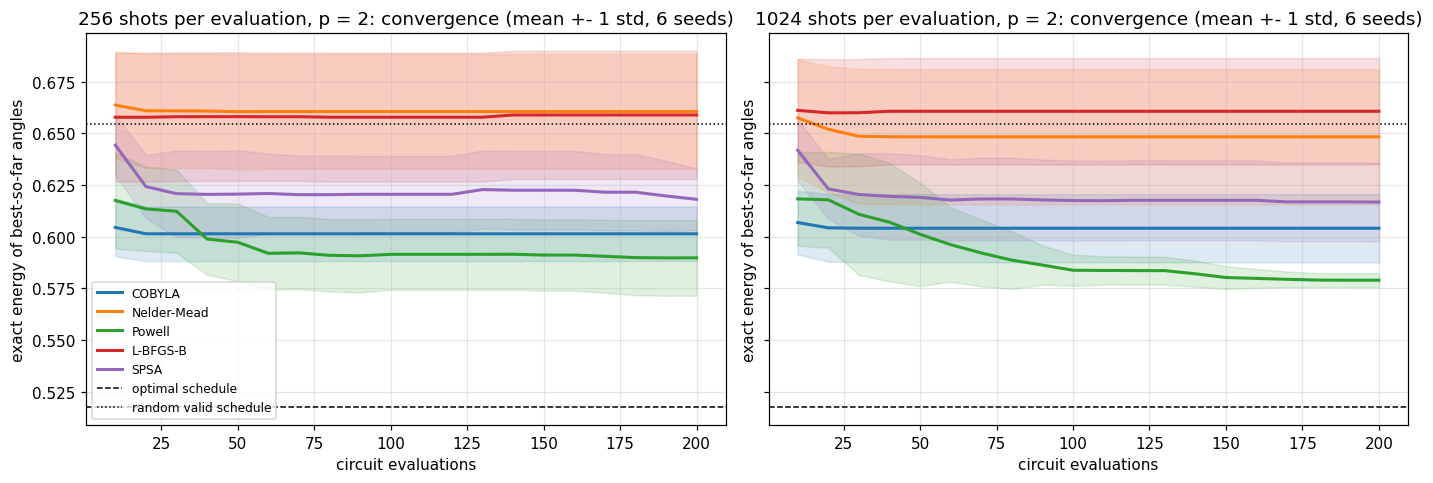

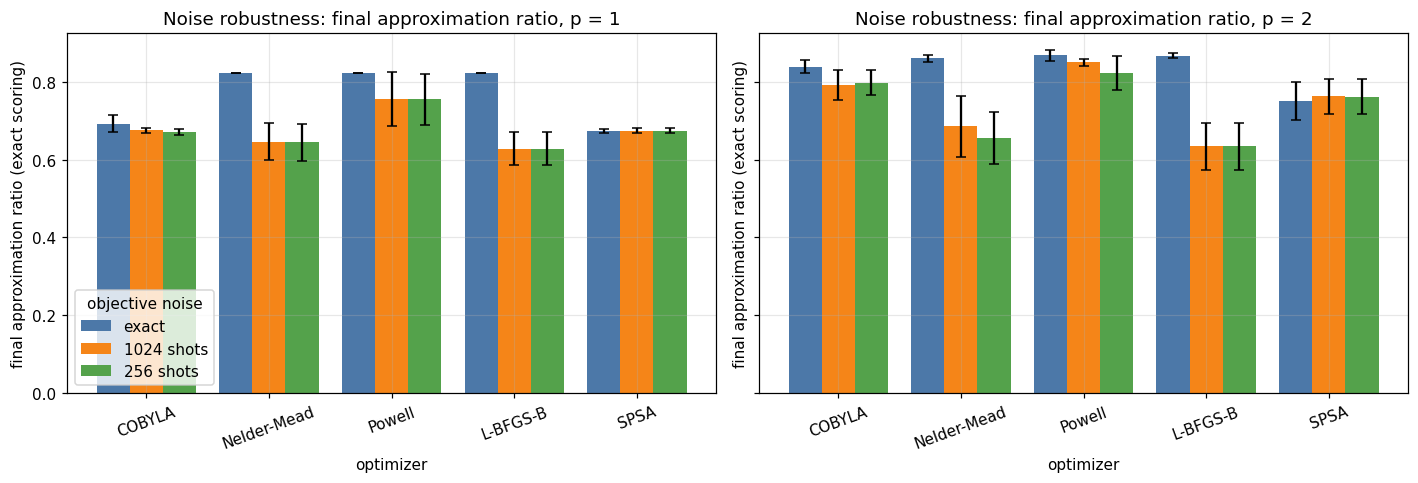

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, shots in zip(axes, (256, 1024)):
    for m in METHODS:
        c = exp2_curves[(shots, 2, m)]
        ax.plot(xs_n, c.mean(0), color=COLORS[m], label=m, lw=2)
        ax.fill_between(xs_n, c.mean(0) - c.std(0), c.mean(0) + c.std(0), color=COLORS[m], alpha=0.15)
    ax.axhline(E_best, color='k', ls='--', lw=1, label='optimal schedule')
    ax.axhline(E_mean, color='k', ls=':', lw=1, label='random valid schedule')
    ax.set_title(f'{shots} shots per evaluation, p = 2: convergence (mean +- 1 std, 6 seeds)')
    ax.set_xlabel('circuit evaluations'); ax.set_ylabel('exact energy of best-so-far angles')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'convergence_noisy.png'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
width = 0.27
for ax, p in zip(axes, (1, 2)):
    for j, (lab, get) in enumerate([('exact', lambda m: exp1[(p, m)]),
                                    ('1024 shots', lambda m: exp2[(1024, p, m)]),
                                    ('256 shots', lambda m: exp2[(256, p, m)])]):
        mu = [get(m)['approx_ratio'][0] for m in METHODS]; sd = [get(m)['approx_ratio'][1] for m in METHODS]
        ax.bar(np.arange(5) + (j - 1) * width, mu, width, yerr=sd, capsize=3, label=lab,
               color=['#4c78a8', '#f58518', '#54a24b'][j])
    ax.set_xticks(range(5)); ax.set_xticklabels(METHODS, rotation=20)
    ax.set_title(f'Noise robustness: final approximation ratio, p = {p}')
    ax.set_xlabel('optimizer'); ax.set_ylabel('final approximation ratio (exact scoring)')
axes[0].legend(title='objective noise')
plt.tight_layout(); plt.savefig(OUT / 'approx_ratio_noisy.png'); plt.show()

## Experiment 3 - CVaR-alpha objective under shots
With `shots` sampled bitstrings the objective is the **mean of the lowest `alpha` fraction of their energies**. `alpha = 1` is the ordinary expectation, small alpha only rewards the luckiest samples. The primary metrics are P(optimal schedule) and P(within 1% of optimum) evaluated **exactly** at the final angles. We use COBYLA and SPSA at 1024 shots, budget 150, 6 seeds.

In [10]:
ALPHAS, BUDGET_C, SHOTS_C = [0.1, 0.25, 0.5, 1.0], 150, 1024
exp3 = {}
for p in (1, 2):
    for m in ('COBYLA', 'SPSA'):
        for a in ALPHAS:
            rows = []
            for s in SEEDS_NOISY:
                f = shot_objective(p, SHOTS_C, np.random.default_rng(2000 + s), alpha=a)
                res = run_optimizer(f, start_point(p, s), m, BUDGET_C, seed=s)
                rows.append({**final_metrics(p, res['x']), 'nfev': res['nfev']})
            exp3[(p, m, a)] = summarise(rows)
print(f'Experiment 3 done  ({time.time() - T0:.0f}s elapsed)')
print(f"{'p':>2} {'opt':<8}{'alpha':>6}{'P(opt)':>16}{'P(<=1%)':>16}{'approx ratio':>14}")
for (p, m, a), s in exp3.items():
    print(f"{p:>2} {m:<8}{a:>6}{s['p_optimal'][0]:>10.3f}+-{s['p_optimal'][1]:.3f}"
          f"{s['p_within_1pct'][0]:>10.3f}+-{s['p_within_1pct'][1]:.3f}{s['approx_ratio'][0]:>14.3f}")

Experiment 3 done  (397s elapsed)
 p opt      alpha          P(opt)         P(<=1%)  approx ratio
 1 COBYLA     0.1     0.029+-0.002     0.029+-0.002         0.679
 1 COBYLA    0.25     0.028+-0.001     0.028+-0.001         0.675
 1 COBYLA     0.5     0.027+-0.001     0.027+-0.001         0.677
 1 COBYLA     1.0     0.023+-0.005     0.023+-0.005         0.675
 1 SPSA       0.1     0.028+-0.001     0.028+-0.001         0.673
 1 SPSA      0.25     0.028+-0.001     0.028+-0.001         0.674
 1 SPSA       0.5     0.028+-0.001     0.028+-0.001         0.674
 1 SPSA       1.0     0.028+-0.001     0.028+-0.001         0.675
 2 COBYLA     0.1     0.118+-0.021     0.118+-0.021         0.787
 2 COBYLA    0.25     0.118+-0.021     0.118+-0.021         0.788
 2 COBYLA     0.5     0.131+-0.008     0.131+-0.008         0.805
 2 COBYLA     1.0     0.136+-0.009     0.136+-0.009         0.813
 2 SPSA       0.1     0.096+-0.028     0.096+-0.028         0.752
 2 SPSA      0.25     0.099+-0.033     0.099

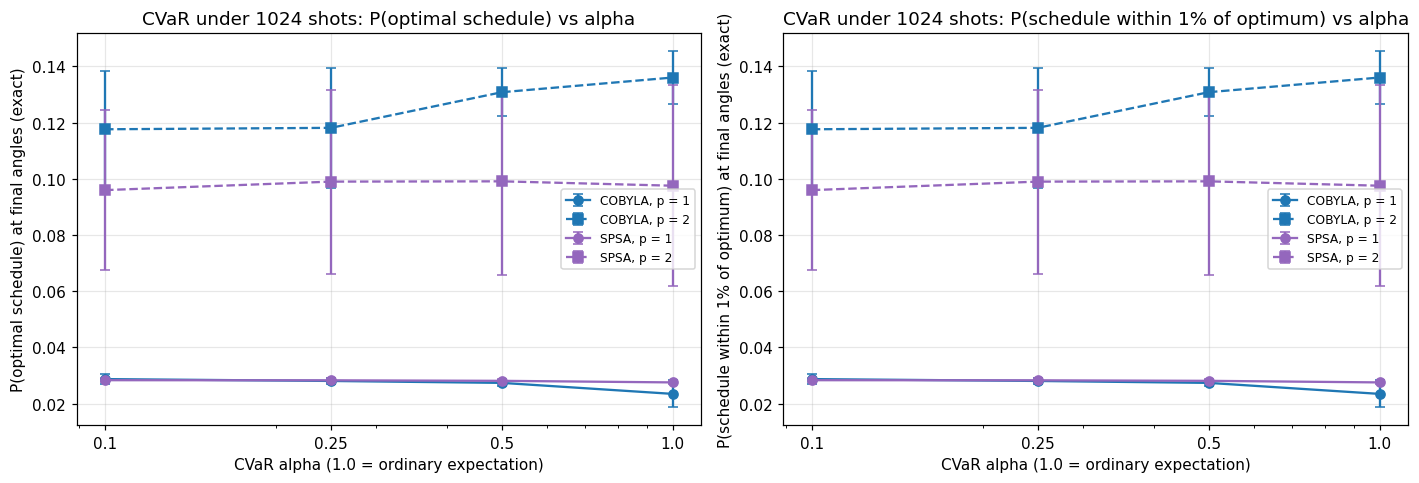

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {('COBYLA', 1): ('-o', '#1f77b4'), ('COBYLA', 2): ('--s', '#1f77b4'),
          ('SPSA', 1): ('-o', '#9467bd'), ('SPSA', 2): ('--s', '#9467bd')}
for ax, (metric, title) in zip(axes, [('p_optimal', 'P(optimal schedule)'), ('p_within_1pct', 'P(schedule within 1% of optimum)')]):
    for (m, p), (st, col) in styles.items():
        mu = [exp3[(p, m, a)][metric][0] for a in ALPHAS]; sd = [exp3[(p, m, a)][metric][1] for a in ALPHAS]
        ax.errorbar(ALPHAS, mu, yerr=sd, fmt=st, color=col, capsize=3, label=f'{m}, p = {p}')
    ax.set_xscale('log'); ax.set_xticks(ALPHAS); ax.set_xticklabels(ALPHAS)
    ax.set_title(f'CVaR under {SHOTS_C} shots: {title} vs alpha'); ax.set_xlabel('CVaR alpha (1.0 = ordinary expectation)')
    ax.set_ylabel(title + ' at final angles (exact)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'cvar_vs_alpha.png'); plt.show()

In [12]:
def enc(d): return {' | '.join(map(str, k)): v for k, v in d.items()}
RUNTIME = time.time() - T0
json.dump({'config': {'success_ratio': SUCCESS_RATIO, 'budget_exact': BUDGET, 'budget_noisy': BUDGET_N,
                      'budget_cvar': BUDGET_C, 'seeds_exact': len(SEEDS_EXACT), 'seeds_noisy': len(SEEDS_NOISY),
                      'E_best': E_best, 'E_mean': E_mean, 'E_worst': E_worst, 'runtime_s': RUNTIME},
           'exp1_exact': enc(exp1), 'exp2_noisy': enc(exp2), 'exp3_cvar': enc(exp3)},
          open(OUT / 'results.json', 'w'), indent=2)
print(f'saved results.json and PNGs to {OUT}; total runtime {RUNTIME:.0f}s')

saved results.json and PNGs to /Users/sakxamshrestha/Desktop/IQ-hackathon/ev-qaoa-iq/results/04_optimizers; total runtime 398s


## Findings & limitations

Numbers below come from the tables printed above (also in `results/04_optimizers/results.json`). Approximation ratio = 1 means the optimal schedule; a random valid schedule scores 0.67 on average here (so COBYLA at p = 1 is barely better than random guessing). Success = final ratio >= 0.80. Six valid schedules tie at the optimal energy, which is why P(optimal) equals P(within 1%) everywhere.

**Exact energy (8 seeds, 200 evaluation budget)**
- p = 1: Nelder-Mead, Powell and L-BFGS-B all reach the same ratio **0.822** from every seed (100% success), using about 133, 85 and 78 evaluations. COBYLA stalls at **0.692** (0% success) and COBYLA capped at 30 evaluations (the upstream setting) reaches **0.681**. Our SPSA reaches 0.674. The better optimizers raise P(optimal) from 0.027 to **0.106** (about 4x) without changing the circuit.
- p = 2: every optimizer improves. Powell 0.868, L-BFGS-B 0.867, Nelder-Mead 0.860, COBYLA 0.839 (all 100% success); L-BFGS-B has the highest P(optimal) at 0.159 (COBYLA 0.154). COBYLA capped at 30 evals already gets 0.822 (88% success), so the cap costs little at p = 2 but a lot at p = 1 only because COBYLA gets stuck there. SPSA is weakest at 0.751 (25% success) with 199 evaluations.

**Shot noise (6 seeds, 200 evaluation budget)**
- L-BFGS-B collapses as expected: finite-difference gradients are dominated by sampling noise (p = 2: 0.634 at both 256 and 1024 shots, down from 0.867 exact; 0% success).
- Nelder-Mead also degrades badly (p = 2: 0.656 at 256 shots, 0.685 at 1024; 0% success).
- Powell and COBYLA are the most robust at p = 2: Powell 0.823 (256 shots) and 0.850 (1024 shots); COBYLA 0.798 and 0.792. COBYLA terminates early under noise (28-46 evaluations used), so it is cheap but may stop before converging.
- SPSA is unaffected by noise (p = 2: 0.762 at both shot counts, about the same as exact) but converges slowly and is not the best in absolute terms in our budget.
- Powell at p = 1 is only partially reliable under noise (0.755, 50% success).

**CVaR (1024 shots, 150 evaluations, 6 seeds)**
- In our experiments CVaR did **not** clearly help. COBYLA at p = 2: P(optimal) 0.118 (alpha 0.1), 0.118 (0.25), 0.131 (0.5), 0.136 (1.0 = ordinary expectation), so the plain expectation was slightly best. At p = 1 the differences (0.023 to 0.029) are inside one standard deviation of the seeds. SPSA shows no alpha dependence (p = 2: 0.096 to 0.099).
- Likely reasons: with the XY mixer and Dicke start every sample is a valid schedule, 1024 shots already estimate the mean well, and a small alpha keeps only a few samples so the objective itself gets noisier. CVaR is more likely to matter with infeasible samples (X mixer, penalty terms) or very low p, which we did not test.

**Recommendation.** For exact or low-noise evaluation use Powell (or L-BFGS-B if the gradient cost of 2p+1 evaluations per step is affordable). On shot-limited hardware use Powell or COBYLA, and avoid L-BFGS-B and Nelder-Mead. Moving from p = 1 to p = 2 improved the final ratio for every optimizer in the exact runs, a larger effect than CVaR.

**Limitations.** Statevector simulation with multinomial shot noise only: no gate or readout noise (see notebook 05). One instance (EXAMPLE_3x4), 6 to 8 seeds, so error bars are rough and small differences (for example COBYLA vs Powell at 1024 shots) are not statistically established. SPSA gains were lightly tuned (a = 3.0 chosen from {0.3, 1, 3, 10} on 4 exact p = 1 starts); other settings or more evaluations might help. COBYLA's failure at p = 1 was not fixed by smaller initial steps (rhobeg 0.1 to 1.0 all gave about 0.67 to 0.69 in a quick check), so it appears to be a genuine local optimum, but we did not map the landscape. Random starts are uniform on [0, pi], which is not an optimised initialisation. Runtime of the whole notebook is about 6.5 minutes.